<h1 style="text-align: center;"><strong>Differentiated Problem Solving</strong></h1>
<h2 style="text-align: center;"><strong>Global Solution 2026.2 — CitizenTech</strong></h2>
<h3 style="text-align: center;"><strong>Olho na Via: do chamado ao reparo — limites, derivadas e integrais aplicados aos buracos de São Paulo</strong></h3>
<h4 style="text-align: center;"><strong>FIAP — Engenharia de Software · 1º ano · 2026.2</strong></h4>
<br>
<br>

---

# **Objetivo da atividade**

Este notebook aplica **limites, derivadas e integrais** a um fenômeno urbano real: os pedidos de **tapa-buraco** registrados pelos cidadãos no **SP156**, a central de atendimento da Prefeitura de São Paulo. Os dados são **microdados oficiais** do Portal de Dados Abertos da Prefeitura, cobrindo 2025 e os três primeiros trimestres de 2026.

O trabalho subsidia tecnicamente o protótipo **Olho na Via**, CitizenTech que usa ônibus e câmeras públicas para detectar buracos, abrir chamados automaticamente e confirmar o reparo. As perguntas que orientam a análise são:

1. **Quando a demanda cresce ou cai e quanto ela acumula?** (derivadas, extremos e integral da taxa de pedidos)
2. **Quando a fila de pedidos sem resposta aumenta?** (integral de entradas menos saídas e sua derivada)
3. **Quanto tempo um buraco espera e onde está o maior custo da espera?** (limites, derivada e integral imprópria de uma curva exponencial)

**Questão orientadora:** a cidade perde mais com a demora típica ou com os poucos buracos que ficam abertos por muito tempo? A resposta orienta como o Olho na Via deve priorizar os chamados.

O material está organizado em **4 partes**: demanda semanal (Parte 1), estoque de pedidos (Parte 2), tempo até o reparo (Parte 3) e decisão para o protótipo (Parte 4).

---

# **Da proposta inicial ao modelo com dados reais**

O documento-base do Olho na Via propunha, para esta disciplina, um modelo **hipotético** de crescimento do buraco, $A(t)=A_0e^{kt}$, com o custo acumulado do atraso dado por uma integral, e a escolha dos ônibus por cobertura. Ao confrontar a proposta com os conteúdos e o padrão das aulas, ela foi ajustada:

| Proposta inicial | Avaliação | Ajuste feito neste trabalho |
|:--|:--|:--|
| Crescimento exponencial com $k=0{,}10$/dia arbitrado | Sem dado real; a revisão para a GS exige dados com fonte identificada | Modelos ajustados por **mínimos quadrados** aos microdados do SP156; $k$ entra só como cenário de sensibilidade |
| Custo acumulado por integral | Adequado (integrais, Aulas 18 e 19) | Mantido como **integral imprópria** do tempo de espera e do dano |
| Escolha dos ônibus por cobertura | Problema combinatório, fora de limites, derivadas e integrais | Retirado desta disciplina; fica para a lógica em Python |
| Limites não apareciam | O objetivo pede comportamento extremo | Derivada **pela definição**, limites no infinito, extrapolação e convergência |

O resultado é um modelo menos especulativo e mais útil para a decisão: os números vêm da própria cidade.

---

## **Identificação dos alunos**

In [1]:
#@title Identificação
Nome_1 = "Erick Nathan Capito Pereira" #@param {type:"string"}
RM_1 = "573635" #@param {type:"string"}

---

# **Configuração visual e imports**

Mantemos o padrão das aulas: texto serifado, fórmulas em MathJax e gráficos em `viridis`. Os dados ficam na pasta `dados/`, ao lado deste notebook; não é preciso conexão com a internet.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sympy as sp
from matplotlib import font_manager
from IPython.display import display, HTML, Markdown
from scipy.integrate import quad, trapezoid, cumulative_trapezoid
from scipy.optimize import curve_fit

# CSS aplicado apenas à renderização textual das células Markdown.
display(HTML("""
<style>
.jp-RenderedHTMLCommon, .text_cell_render, .colab-markdown {
    font-family: 'Latin Modern Roman', 'CMU Serif', Georgia, 'DejaVu Serif', serif;
    font-size: 18px;
    line-height: 1.6;
}
</style>
"""))

fontes_disponiveis = {f.name for f in font_manager.fontManager.ttflist}
fontes_preferidas = ["Latin Modern Roman", "CMU Serif", "Georgia", "DejaVu Serif"]
fonte_grafico = next((f for f in fontes_preferidas if f in fontes_disponiveis), "DejaVu Serif")

sns.set_theme(style="whitegrid", palette="viridis", font=fonte_grafico)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [fonte_grafico] + fontes_preferidas,
    "mathtext.fontset": "cm",
    "text.usetex": False,
    "figure.figsize": (9, 5.2),
    "figure.dpi": 110,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.18,
    "grid.linewidth": 0.7,
})
pd.set_option("display.float_format", lambda valor: f"{valor:.4f}")
np.set_printoptions(suppress=True, precision=4)
cmap = plt.get_cmap("viridis")
print(f"Fonte dos gráficos: {fonte_grafico}")

Fonte dos gráficos: Georgia


---

# **Base de dados e contexto do problema**

Os dados vêm do conjunto **"Dados do SP156 – Solicitações"**, publicado pela Prefeitura de São Paulo no seu Portal de Dados Abertos. Cada linha do arquivo original é um protocolo aberto por um cidadão, com data de abertura, data de finalização, serviço e status.

- **Fonte:** [Portal de Dados Abertos da Prefeitura de São Paulo — Dados do SP156](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156).
- **Arquivos usados:** trimestres 1 a 4 de 2025 e 1 a 3 de 2026 (cerca de 4,1 milhões de protocolos de todos os serviços).
- **Recorte:** serviço **"Tapa-buraco"** (assunto "Reparos em asfalto, pontes, viadutos e túneis").
- **Data da consulta:** 09/11/2026.
- **Natureza dos dados:** registros reais, agregados por nós; nenhum valor foi gerado ou simulado.
- **Reprodutibilidade:** o script `preparar_dados.py` mostra como os microdados viraram as três bases da pasta `dados/`.

| Base | Variável | Interpretação | Unidade |
|:--|:--|:--|:--|
| `tapa_buraco_semanal.csv` | `pedidos` | Pedidos abertos na semana (segunda a domingo) | pedidos |
| `coorte_2025_diaria.csv` | `entradas` | Pedidos de 2025 abertos no dia | pedidos |
| | `finalizadas`, `canceladas` | Pedidos de 2025 encerrados no dia | pedidos |
| `sobrevivencia_2025.csv` | `fracao_sem_reparo` | Fração dos pedidos de 2025 ainda sem reparo após `dias` dias | adimensional |

**Convenções importantes.**

- **Pedido não é buraco:** um mesmo buraco pode gerar vários pedidos, e muitos buracos nunca são reportados.
- **Semana como unidade de tempo na Parte 1:** a demanda tem um ciclo semanal forte (cerca de 380 pedidos por dia útil contra cerca de 150 aos domingos). Somar por semana remove esse ciclo. O valor semanal é interpretado como a taxa $q(t)$ em **pedidos/semana**, no ponto médio da semana.
- **Corte de observação:** os arquivos de 2025 foram extraídos com finalizações até **06/08/2026**. Assim, todo pedido de 2025 tem pelo menos 218 dias de acompanhamento.

**Limitações conhecidas.**

- O arquivo do 1º trimestre de 2025 tem exatamente 1.048.575 linhas, o limite de uma planilha do Excel. Isso indica possível corte de registros de **outros** serviços, mas o total de tapa-buraco de 2025 confere com o número oficial (113,1 mil).
- O arquivo do 3º trimestre de 2026 usa vírgula como separador e datas no formato mês/dia. O script de preparação detecta e trata as duas diferenças.

In [3]:
PASTA_DADOS = Path("dados")
semanal = pd.read_csv(PASTA_DADOS / "tapa_buraco_semanal.csv", parse_dates=["inicio_semana", "fim_semana"])
coorte = pd.read_csv(PASTA_DADOS / "coorte_2025_diaria.csv", parse_dates=["data"])
sobrevivencia = pd.read_csv(PASTA_DADOS / "sobrevivencia_2025.csv")

print(f"Semanas: {len(semanal)} | dias da coorte 2025: {len(coorte)} | pontos da curva de sobrevivência: {len(sobrevivencia)}")
display(semanal.head(5))

Semanas: 90 | dias da coorte 2025: 583 | pontos da curva de sobrevivência: 219


,inicio_semana,fim_semana,pedidos
0,2025-01-06,2025-01-12,2280
1,2025-01-13,2025-01-19,2577
2,2025-01-20,2025-01-26,2292
3,2025-01-27,2025-02-02,3077
4,2025-02-03,2025-02-09,3441


---

# **Conceitos e fórmulas de apoio**

**Ajuste por mínimos quadrados e medidas de ajuste**

$$
\min_{\theta}\sum_{i=1}^{n}\left[y_i-f_{\theta}(t_i)\right]^2,\qquad
R^2=1-\frac{\sum(y_i-\widehat y_i)^2}{\sum(y_i-\bar y)^2},\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum(y_i-\widehat y_i)^2}.
$$

**Derivada pela definição, pontos críticos e inflexão**

$$
q'(t)=\lim_{h\to 0}\frac{q(t+h)-q(t)}{h}.
$$

Pontos com $q'(t)=0$ são candidatos a extremos; $q''(t)$ classifica-os. Pontos com $q''(t)=0$ e troca de sinal são **inflexões**: neles a própria taxa de variação atinge um extremo, ou seja, é onde a demanda cresce ou cai **mais rápido**.

**Integral, acumulação e Teorema Fundamental do Cálculo**

$$
\int_a^b q(t)\,dt = Q(b)-Q(a),\qquad
B(t)=B(0)+\int_0^t\big[e(s)-s(s)\big]\,ds\ \Longrightarrow\ B'(t)=e(t)-s(t).
$$

**Curva de sobrevivência, taxa de reparo e integral imprópria**

Se $T$ é o tempo (em dias) até o reparo de um buraco, $S(d)=P(T>d)$ é a fração ainda sem reparo após $d$ dias. Então:

$$
h(d)=-\frac{S'(d)}{S(d)}\quad\text{(chance diária de reparo de quem ainda espera)},\qquad
\mathbb{E}[T]=\int_0^{\infty}S(d)\,dd=\lim_{T\to\infty}\int_0^{T}S(d)\,dd.
$$

A integral imprópria só tem valor finito se o limite existir. Esse ponto é central na Parte 3.

---

# **Parte 1 — Demanda semanal de tapa-buraco em 2025**

**1.a — Auditoria dos dados.** Antes de modelar, conferimos se a base responde à pergunta: total anual, semanas completas, ausência de valores negativos ou faltantes e coerência com o número oficial divulgado pela Secretaria Municipal das Subprefeituras (**113,1 mil pedidos em 2025**).

In [4]:
total_2025 = int(coorte["entradas"].sum())
checagens = {
    "Total de 2025 igual ao divulgado pela SMSUB (113,1 mil)": round(total_2025 / 1000, 1) == 113.1,
    "Semanas completas e consecutivas": (semanal["fim_semana"].diff().dropna() == pd.Timedelta(days=7)).all(),
    "Sem contagens negativas": (semanal["pedidos"] >= 0).all() and (coorte[["entradas", "finalizadas", "canceladas"]] >= 0).all().all(),
    "Sem valores ausentes": not (semanal.isna().any().any() or coorte.isna().any().any()),
    "Sobrevivência não crescente": (np.diff(sobrevivencia["fracao_sem_reparo"]) <= 1e-12).all(),
}
display(pd.DataFrame({"Critério": list(checagens), "Atendido": [bool(v) for v in checagens.values()]}))
assert all(checagens.values()), "Há alguma inconsistência a investigar."

total_formatado = f"{total_2025:,}".replace(",", ".")
display(Markdown(f"""
**Interpretação.** Todos os testes foram atendidos. O total de **{total_formatado} pedidos de tapa-buraco em 2025**
coincide com o número divulgado pela Prefeitura (113,1 mil), o que valida a filtragem dos microdados.
Não há motivo para excluir ou alterar observações.
"""))

,Critério,Atendido
0,Total de 2025 igual ao divulgado pela SMSUB (1...,True
1,Semanas completas e consecutivas,True
2,Sem contagens negativas,True
3,Sem valores ausentes,True
4,Sobrevivência não crescente,True



**Interpretação.** Todos os testes foram atendidos. O total de **113.086 pedidos de tapa-buraco em 2025**
coincide com o número divulgado pela Prefeitura (113,1 mil), o que valida a filtragem dos microdados.
Não há motivo para excluir ou alterar observações.


**1.b — Leitura quantitativa, gráfico e taxa média de variação.** Usamos as **51 semanas completas** de 2025 (06/01 a 28/12). O tempo $t$ é medido em semanas desde 06/01/2025, no ponto médio de cada semana ($t=0{,}5;\ 1{,}5;\ \dots;\ 50{,}5$).

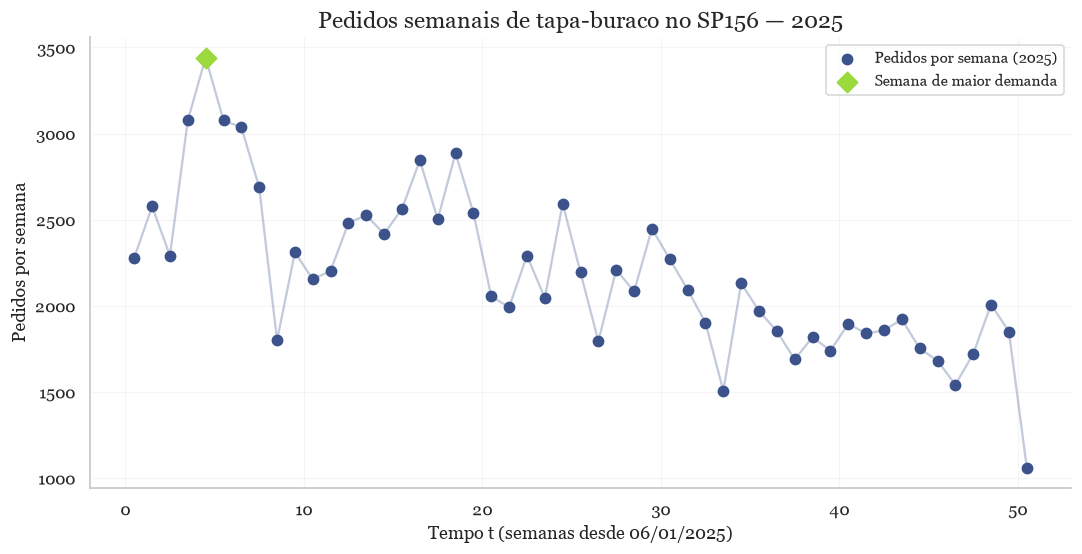


- Pedidos nas 51 semanas: **111524** · média: **2186.7 pedidos/semana**.
- Maior demanda: **3441 pedidos** na semana de 03/02/2025; menor: **1062** na semana de 22/12/2025 (Natal).

**Taxa média de variação** entre $t=5.5$ (fevereiro) e $t=45.5$ (novembro):

$$
\frac{q(45.5)-q(5.5)}{45.5-5.5}=\frac{1682-3076}{40}=\boxed{-34.85\ \mathrm{pedidos/semana^2}}.
$$

Em média, a demanda caiu cerca de 35 pedidos por semana a cada semana entre fevereiro e novembro. Esse quociente usa só
dois pontos; a derivada de um modelo ajustado descreve a variação **instantânea** e pode ser diferente em cada trecho.


In [5]:
s25 = semanal[semanal["fim_semana"].dt.year == 2025].reset_index(drop=True)
s26 = semanal[semanal["fim_semana"].dt.year == 2026].reset_index(drop=True)
tempo = np.arange(len(s25)) + 0.5
taxa = s25["pedidos"].to_numpy(dtype=float)
i_max, i_min = int(np.argmax(taxa)), int(np.argmin(taxa))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.scatter(tempo, taxa, color=cmap(0.25), s=45, label="Pedidos por semana (2025)", zorder=3)
ax.plot(tempo, taxa, color=cmap(0.25), alpha=0.3)
ax.scatter([tempo[i_max]], [taxa[i_max]], marker="D", s=90, color=cmap(0.85), label="Semana de maior demanda", zorder=4)
ax.set(title="Pedidos semanais de tapa-buraco no SP156 — 2025",
       xlabel="Tempo t (semanas desde 06/01/2025)", ylabel="Pedidos por semana")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

ta, tb = tempo[5], tempo[45]
taxa_media_variacao = (taxa[45] - taxa[5]) / (tb - ta)
display(Markdown(f"""
- Pedidos nas 51 semanas: **{int(taxa.sum())}** · média: **{taxa.mean():.1f} pedidos/semana**.
- Maior demanda: **{taxa[i_max]:.0f} pedidos** na semana de {s25['inicio_semana'][i_max]:%d/%m/%Y}; menor: **{taxa[i_min]:.0f}** na semana de {s25['inicio_semana'][i_min]:%d/%m/%Y} (Natal).

**Taxa média de variação** entre $t={ta}$ (fevereiro) e $t={tb}$ (novembro):

$$
\\frac{{q({tb})-q({ta})}}{{{tb}-{ta}}}=\\frac{{{taxa[45]:.0f}-{taxa[5]:.0f}}}{{{tb-ta:.0f}}}=\\boxed{{{taxa_media_variacao:.2f}\\ \\mathrm{{pedidos/semana^2}}}}.
$$

Em média, a demanda caiu cerca de 35 pedidos por semana a cada semana entre fevereiro e novembro. Esse quociente usa só
dois pontos; a derivada de um modelo ajustado descreve a variação **instantânea** e pode ser diferente em cada trecho.
"""))

**1.c — Ajuste de dois modelos por mínimos quadrados.** Estimamos um polinômio de grau 2 e outro de grau 3 com `numpy.polyfit`. O objetivo não é passar por todos os pontos, mas descrever a **tendência** do ano.


$$
q_2(t)=-0.101419t^2 -18.358419t +2742.8063
$$

$$
q_3(t)=0.00922867t^3 -0.807412t^2 -3.95292t +2681.514
$$

Domínio do ajuste: $0{,}5\leq t\leq 50{,}5$ semanas. $[q]=\mathrm{pedidos/semana}$ e $[t]=\mathrm{semana}$.
Em $q_3$: $[a]=\mathrm{pedidos/semana^4}$, $[b]=\mathrm{pedidos/semana^3}$, $[c]=\mathrm{pedidos/semana^2}$, $[d]=\mathrm{pedidos/semana}$.


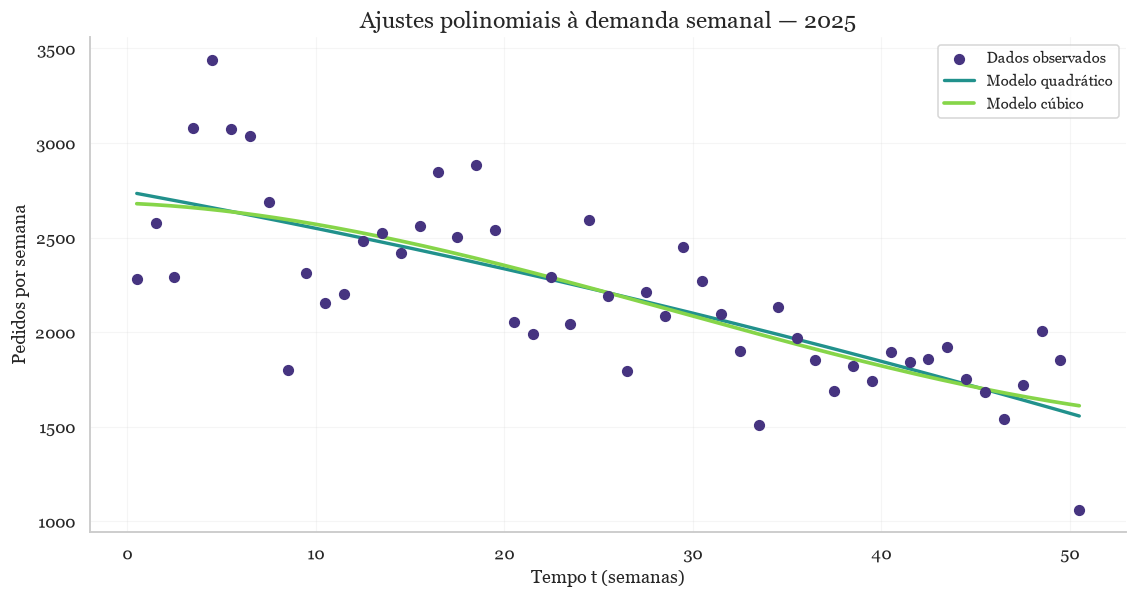

In [6]:
coef_2 = np.polyfit(tempo, taxa, deg=2)
coef_3 = np.polyfit(tempo, taxa, deg=3)
q2, q3 = np.poly1d(coef_2), np.poly1d(coef_3)
a3, b3, c3, d3 = coef_3

display(Markdown(f"""
$$
q_2(t)={coef_2[0]:.6f}t^2 {coef_2[1]:+.6f}t {coef_2[2]:+.4f}
$$

$$
q_3(t)={a3:.8f}t^3 {b3:+.6f}t^2 {c3:+.5f}t {d3:+.3f}
$$

Domínio do ajuste: $0{{,}}5\\leq t\\leq 50{{,}}5$ semanas. $[q]=\\mathrm{{pedidos/semana}}$ e $[t]=\\mathrm{{semana}}$.
Em $q_3$: $[a]=\\mathrm{{pedidos/semana^4}}$, $[b]=\\mathrm{{pedidos/semana^3}}$, $[c]=\\mathrm{{pedidos/semana^2}}$, $[d]=\\mathrm{{pedidos/semana}}$.
"""))

malha = np.linspace(0.5, tempo[-1], 800)
fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.scatter(tempo, taxa, s=40, color=cmap(0.15), label="Dados observados", zorder=4)
ax.plot(malha, q2(malha), color=cmap(0.5), lw=2.2, label="Modelo quadrático")
ax.plot(malha, q3(malha), color=cmap(0.82), lw=2.4, label="Modelo cúbico")
ax.set(title="Ajustes polinomiais à demanda semanal — 2025",
       xlabel="Tempo t (semanas)", ylabel="Pedidos por semana")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**1.d — Precisão e resíduos.** Calculamos $R^2$ e RMSE explicitamente, conferimos por um segundo procedimento e analisamos os resíduos $r_i=y_i-\widehat y_i$.

,SSE,R²,RMSE (pedidos/semana)
Modelo,,,
Grau 2,4529484.8413,0.5754,298.0158
Grau 3,4502334.7653,0.5779,297.1213


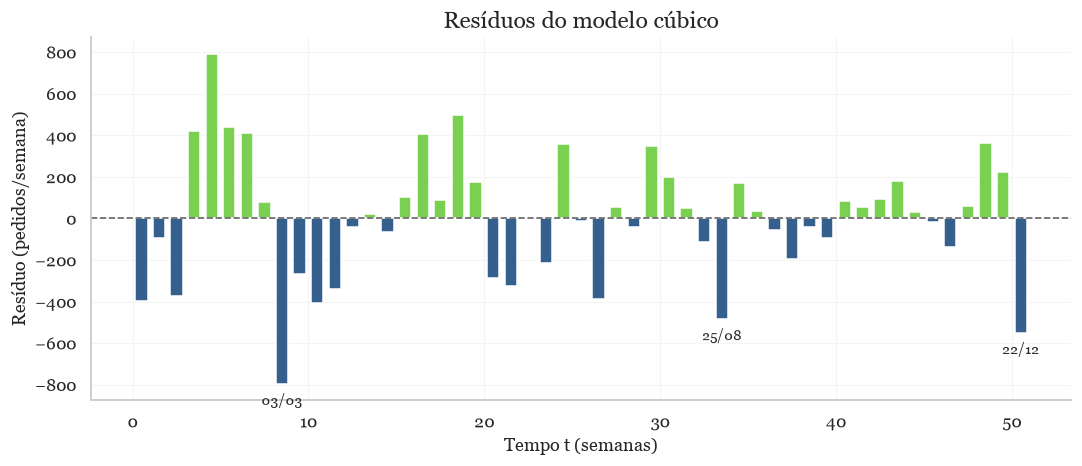


**Interpretação.** Os dois modelos explicam cerca de 58% da variação semanal ($R^2\approx0{,}58$); o termo cúbico
melhora pouco o quadrático. Os maiores resíduos negativos caem em semanas com **feriados** (Carnaval em 03/03,
Natal em 22/12) e em agosto, quando há menos dias úteis de atendimento. Os resíduos positivos do início do ano
mostram que o pico de fevereiro, no auge das chuvas de verão, não é capturado por um polinômio de baixo grau.
O modelo é adequado para a **tendência anual**, não para prever uma semana específica.


In [7]:
soma_quadrados_total = float(np.sum((taxa - taxa.mean()) ** 2))
n = len(taxa)
metricas = []
for grau, modelo in [(2, q2), (3, q3)]:
    residuos = taxa - modelo(tempo)
    sse = float(np.sum(residuos ** 2))
    r2 = 1.0 - sse / soma_quadrados_total
    rmse = float(np.sqrt(sse / n))
    _, residuos_polyfit, posto, _, _ = np.polyfit(tempo, taxa, grau, full=True)
    assert posto == grau + 1
    assert np.isclose(sse, float(residuos_polyfit[0]), rtol=1e-10)
    assert np.isclose(rmse, float(np.linalg.norm(residuos) / np.sqrt(n)), rtol=1e-10)
    metricas.append((f"Grau {grau}", sse, r2, rmse))
display(pd.DataFrame(metricas, columns=["Modelo", "SSE", "R²", "RMSE (pedidos/semana)"]).set_index("Modelo"))

residuos_3 = taxa - q3(tempo)
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.axhline(0, color="0.4", lw=1.1, ls="--")
ax.bar(tempo, residuos_3, width=0.7, color=[cmap(0.8) if r >= 0 else cmap(0.3) for r in residuos_3])
for i in np.argsort(residuos_3)[:3]:
    ax.annotate(f"{s25['inicio_semana'][i]:%d/%m}", (tempo[i], residuos_3[i]), xytext=(0, -14),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Resíduos do modelo cúbico", xlabel="Tempo t (semanas)", ylabel="Resíduo (pedidos/semana)")
plt.tight_layout()
plt.show()

display(Markdown(r"""
**Interpretação.** Os dois modelos explicam cerca de 58% da variação semanal ($R^2\approx0{,}58$); o termo cúbico
melhora pouco o quadrático. Os maiores resíduos negativos caem em semanas com **feriados** (Carnaval em 03/03,
Natal em 22/12) e em agosto, quando há menos dias úteis de atendimento. Os resíduos positivos do início do ano
mostram que o pico de fevereiro, no auge das chuvas de verão, não é capturado por um polinômio de baixo grau.
O modelo é adequado para a **tendência anual**, não para prever uma semana específica.
"""))

**1.e — A derivada pela definição (limite).** Antes de usar as regras de derivação, verificamos que a derivada de $q_3$ é o **limite do quociente de Newton**. O cálculo é feito de forma simbólica com `sympy.limit` e de forma numérica, diminuindo $h$.

In [8]:
t, h = sp.symbols("t h", real=True)
q3_simbolico = sp.Float(a3) * t**3 + sp.Float(b3) * t**2 + sp.Float(c3) * t + sp.Float(d3)
derivada_por_limite = sp.expand(sp.limit((q3_simbolico.subs(t, t + h) - q3_simbolico) / h, h, 0))
derivada_cubica = np.polyder(q3)
coef_limite = [float(c) for c in sp.Poly(derivada_por_limite, t).all_coeffs()]
assert np.allclose(coef_limite, derivada_cubica.coeffs, rtol=1e-9)
print("Derivada obtida pelo limite:", sp.N(derivada_por_limite, 8))

t0 = 20.5
tabela_limite = pd.DataFrame({
    "h": [1, 0.1, 0.01, 0.001, 0.0001],
    "[q3(t0+h) - q3(t0)] / h": [(q3(t0 + hh) - q3(t0)) / hh for hh in [1, 0.1, 0.01, 0.001, 0.0001]],
})
display(tabela_limite)
display(Markdown(f"""
Quando $h\\to0$, o quociente se aproxima de $q_3'({t0})={derivada_cubica(t0):.4f}$ pedidos/semana².
Isso confirma, numericamente, a definição $q'(t)=\\lim_{{h\\to0}}\\frac{{q(t+h)-q(t)}}{{h}}$.
"""))

Derivada obtida pelo limite: 0.027686022*t**2 - 1.6148244*t - 3.9529208


,h,[q3(t0+h) - q3(t0)] / h
0,1.0000,-25.6524
1,0.1000,-25.4457
2,0.0100,-25.4242
3,0.0010,-25.4220
4,0.0001,-25.4218



Quando $h\to0$, o quociente se aproxima de $q_3'(20.5)=-25.4218$ pedidos/semana².
Isso confirma, numericamente, a definição $q'(t)=\lim_{h\to0}\frac{q(t+h)-q(t)}{h}$.


**1.f — Derivadas em três pontos, pontos críticos, inflexão e extremos.** Pela regra da potência,

$$
q_3(t)=at^3+bt^2+ct+d\ \Longrightarrow\ q_3'(t)=3at^2+2bt+c,\qquad q_3''(t)=6at+2b.
$$

**Derivadas em três instantes (cálculo manual conferido com `numpy.polyder`):**

- $q_3'(5.5)=(0.027686)(5.5)^2+(-1.614824)(5.5)+(-3.95292)=\boxed{-11.997}$ pedidos/semana²
- $q_3'(25.5)=(0.027686)(25.5)^2+(-1.614824)(25.5)+(-3.95292)=\boxed{-27.128}$ pedidos/semana²
- $q_3'(45.5)=(0.027686)(45.5)^2+(-1.614824)(45.5)+(-3.95292)=\boxed{-20.110}$ pedidos/semana²


**Pontos críticos.** Resolvendo $q_3'(t)=0$ pela fórmula de Bhaskara:

$$
\Delta=B^2-4AC=3.045420,\qquad t_{1,2}=\frac{-B\pm\sqrt{\Delta}}{2A}\ \Rightarrow\ t_1=-2.35,\ t_2=60.68\ \text{semanas}.
$$

**Nenhum dos dois pertence a $[0{,}5;\ 50{,}5]$.** Como $q_3'(t)<0$ em todo o intervalo, o modelo é
**decrescente em 2025**, e os extremos absolutos estão nas extremidades:
máximo $q_3(0{,}5)=2679.3$ e mínimo $q_3(50{,}5)=1611.3$ pedidos/semana.
O mínimo local do modelo, $t_2=60.7$ (março de 2026), está **fora** do período observado.

**Inflexão.** $q_3''(t)=0$ em $t=-b/(3a)=29.16$ semanas (fim de julho). Ali a derivada atinge seu valor mais
negativo, $q_3'(29.2)=-27.50$ pedidos/semana²: é o momento em que a
demanda **caiu mais rápido** no ano.


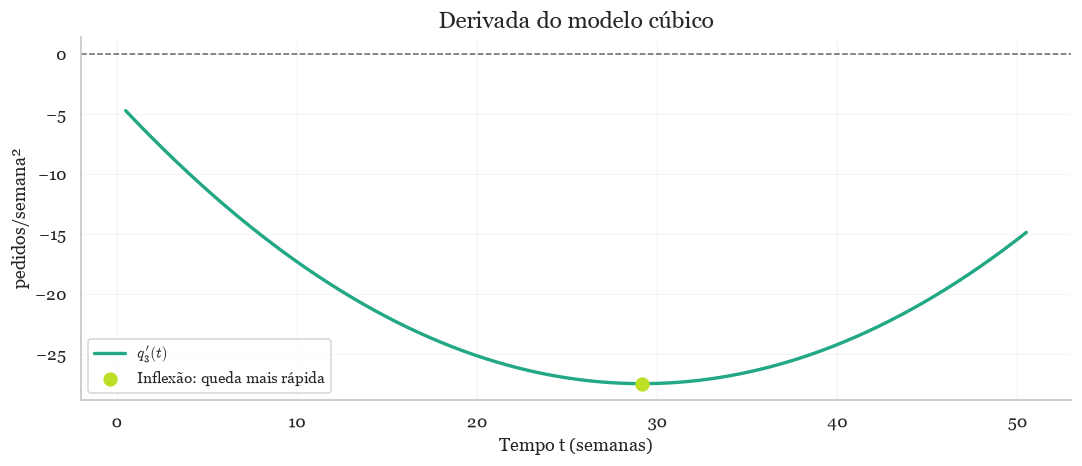

In [9]:
A, B, C = 3 * a3, 2 * b3, c3
contas = []
for instante in [5.5, 25.5, 45.5]:
    valor_manual = A * instante**2 + B * instante + C
    assert np.isclose(valor_manual, derivada_cubica(instante))
    contas.append(f"- $q_3'({instante})=({A:.6f})({instante})^2+({B:.6f})({instante})+({C:.5f})"
                  f"=\\boxed{{{valor_manual:.3f}}}$ pedidos/semana²")

delta = B**2 - 4 * A * C
criticos = sorted([(-B + np.sqrt(delta)) / (2 * A), (-B - np.sqrt(delta)) / (2 * A)])
assert np.allclose(criticos, sorted(np.roots(derivada_cubica).real))
segunda = np.polyder(q3, 2)
t_inflexao = -b3 / (3 * a3)
assert np.isclose(segunda(t_inflexao), 0, atol=1e-9)

display(Markdown(r"**Derivadas em três instantes (cálculo manual conferido com `numpy.polyder`):**" + "\n\n" + "\n".join(contas)))
display(Markdown(f"""
**Pontos críticos.** Resolvendo $q_3'(t)=0$ pela fórmula de Bhaskara:

$$
\\Delta=B^2-4AC={delta:.6f},\\qquad t_{{1,2}}=\\frac{{-B\\pm\\sqrt{{\\Delta}}}}{{2A}}\\ \\Rightarrow\\ t_1={criticos[0]:.2f},\\ t_2={criticos[1]:.2f}\\ \\text{{semanas}}.
$$

**Nenhum dos dois pertence a $[0{{,}}5;\\ 50{{,}}5]$.** Como $q_3'(t)<0$ em todo o intervalo, o modelo é
**decrescente em 2025**, e os extremos absolutos estão nas extremidades:
máximo $q_3(0{{,}}5)={q3(0.5):.1f}$ e mínimo $q_3(50{{,}}5)={q3(50.5):.1f}$ pedidos/semana.
O mínimo local do modelo, $t_2={criticos[1]:.1f}$ (março de 2026), está **fora** do período observado.

**Inflexão.** $q_3''(t)=0$ em $t=-b/(3a)={t_inflexao:.2f}$ semanas (fim de julho). Ali a derivada atinge seu valor mais
negativo, $q_3'({t_inflexao:.1f})={derivada_cubica(t_inflexao):.2f}$ pedidos/semana²: é o momento em que a
demanda **caiu mais rápido** no ano.
"""))

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(malha, derivada_cubica(malha), color=cmap(0.6), lw=2.2, label="$q_3'(t)$")
ax.axhline(0, color="0.4", ls="--", lw=1)
ax.scatter([t_inflexao], [derivada_cubica(t_inflexao)], color=cmap(0.9), s=70, zorder=3, label="Inflexão: queda mais rápida")
ax.set(title="Derivada do modelo cúbico", xlabel="Tempo t (semanas)", ylabel="pedidos/semana²")
ax.legend()
plt.tight_layout()
plt.show()

**1.g — Integral: total de pedidos pelo modelo.** Integramos $q_3$ termo a termo e aplicamos o Teorema Fundamental do Cálculo. Como cada observação representa uma semana inteira, o intervalo $[0;\ 51]$ cobre exatamente as 51 semanas.

In [10]:
def primitiva_manual(t):
    return a3 / 4 * t**4 + b3 / 3 * t**3 + c3 / 2 * t**2 + d3 * t

integral_ano = primitiva_manual(51) - primitiva_manual(0)
integral_quad, _ = quad(q3, 0, 51)
primitiva_numpy = np.polyint(q3)
assert np.isclose(integral_ano, integral_quad) and np.isclose(integral_ano, primitiva_numpy(51) - primitiva_numpy(0))
soma_real = taxa.sum()
integral_centros = primitiva_manual(50.5) - primitiva_manual(0.5)
area_trapezios = trapezoid(taxa, tempo)

display(Markdown(f"""
$$
Q(t)=\\frac{{a}}{{4}}t^4+\\frac{{b}}{{3}}t^3+\\frac{{c}}{{2}}t^2+dt
={a3/4:.8f}t^4 {b3/3:+.6f}t^3 {c3/2:+.5f}t^2 {d3:+.3f}t
$$

$$
\\int_0^{{51}}q_3(t)\\,dt=Q(51)-Q(0)=\\boxed{{{integral_ano:.1f}\\ \\text{{pedidos}}}}
\\qquad\\text{{contra a soma observada de {soma_real:.0f} pedidos.}}
$$

Entre os centros das semanas ($[0{{,}}5;\\ 50{{,}}5]$): integral do modelo = {integral_centros:.1f}; trapézios sobre os dados = {area_trapezios:.1f} pedidos.

**Interpretação.** O erro no total anual é praticamente nulo: um ajuste por mínimos quadrados com termo constante
equilibra os resíduos positivos e negativos. Isso **não** prova que o modelo acerta os picos (o máximo observado foi
{taxa.max():.0f} pedidos e o modelo nunca passa de {q3(0.5):.0f}). Um bom total não é o mesmo que um bom pico.
"""))


$$
Q(t)=\frac{a}{4}t^4+\frac{b}{3}t^3+\frac{c}{2}t^2+dt
=0.00230717t^4 -0.269137t^3 -1.97646t^2 +2681.514t
$$

$$
\int_0^{51}q_3(t)\,dt=Q(51)-Q(0)=\boxed{111523.6\ \text{pedidos}}
\qquad\text{contra a soma observada de 111524 pedidos.}
$$

Entre os centros das semanas ($[0{,}5;\ 50{,}5]$): integral do modelo = 109379.5; trapézios sobre os dados = 109853.0 pedidos.

**Interpretação.** O erro no total anual é praticamente nulo: um ajuste por mínimos quadrados com termo constante
equilibra os resíduos positivos e negativos. Isso **não** prova que o modelo acerta os picos (o máximo observado foi
3441 pedidos e o modelo nunca passa de 2679). Um bom total não é o mesmo que um bom pico.


**1.h — Comportamento extremo e validação em 2026.** O modelo foi ajustado com dados de 2025. O que acontece quando o usamos fora desse intervalo?

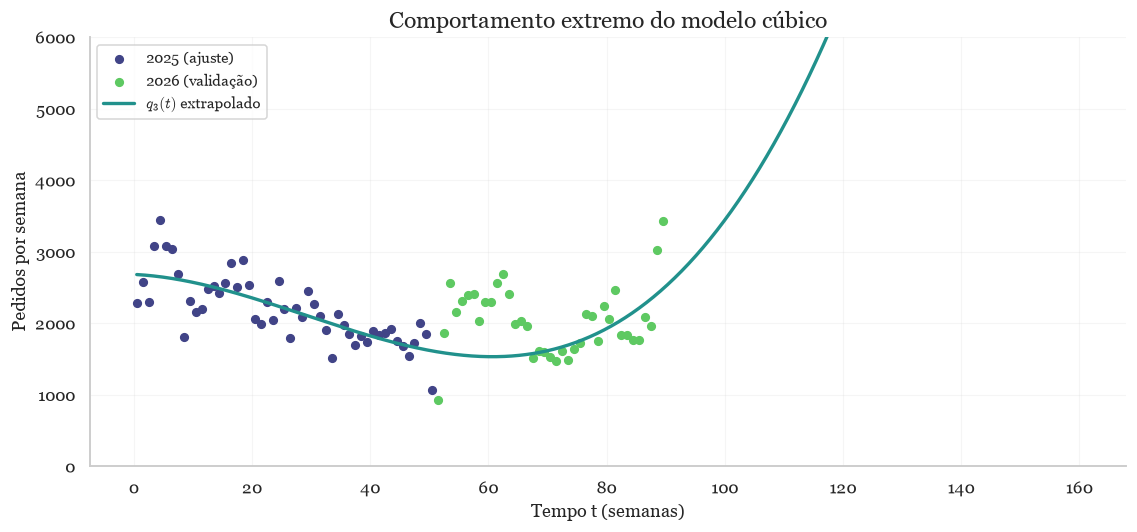


**Limite no infinito.** Como o coeficiente líder é $a=9.23e-03>0$,

$$
\lim_{t\to+\infty}q_3(t)=\lim_{t\to+\infty}t^3\left(a+\frac{b}{t}+\frac{c}{t^2}+\frac{d}{t^3}\right)=+\infty .
$$

O modelo prevê demanda **crescendo sem limite** a partir de março de 2026, o que não tem base física. Já $q_2$, com
coeficiente líder negativo, tende a $-\infty$: preveria **pedidos negativos**. Os dois comportamentos extremos mostram
que polinômios servem para **descrever** o intervalo observado, não para **prever** o futuro.

**Validação (jan–set de 2026, 39 semanas):** observados **79458** pedidos; a integral do
modelo prevê **68976** (-13.2%). A demanda de 2026 voltou a subir com as chuvas de janeiro a março,
contrariando a tendência de queda de 2025. Para o Olho na Via, a lição é: **dimensionar a operação com dados
recentes e atualizados**, não com extrapolação de tendência.


In [11]:
tempo_26 = tempo[-1] + np.arange(1, len(s26) + 1)
obs_26 = s26["pedidos"].to_numpy(dtype=float)
previsto_26 = primitiva_manual(tempo_26[-1] + 0.5) - primitiva_manual(tempo_26[0] - 0.5)
erro_26 = 100 * (previsto_26 - obs_26.sum()) / obs_26.sum()

malha_ext = np.linspace(0.5, 160, 800)
fig, ax = plt.subplots(figsize=(10.5, 5))
ax.scatter(tempo, taxa, s=25, color=cmap(0.2), label="2025 (ajuste)")
ax.scatter(tempo_26, obs_26, s=25, color=cmap(0.75), label="2026 (validação)")
ax.plot(malha_ext, q3(malha_ext), color=cmap(0.5), lw=2.2, label="$q_3(t)$ extrapolado")
ax.set(title="Comportamento extremo do modelo cúbico", xlabel="Tempo t (semanas)", ylabel="Pedidos por semana", ylim=(0, 6000))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

display(Markdown(f"""
**Limite no infinito.** Como o coeficiente líder é $a={a3:.2e}>0$,

$$
\\lim_{{t\\to+\\infty}}q_3(t)=\\lim_{{t\\to+\\infty}}t^3\\left(a+\\frac{{b}}{{t}}+\\frac{{c}}{{t^2}}+\\frac{{d}}{{t^3}}\\right)=+\\infty .
$$

O modelo prevê demanda **crescendo sem limite** a partir de março de 2026, o que não tem base física. Já $q_2$, com
coeficiente líder negativo, tende a $-\\infty$: preveria **pedidos negativos**. Os dois comportamentos extremos mostram
que polinômios servem para **descrever** o intervalo observado, não para **prever** o futuro.

**Validação (jan–set de 2026, {len(s26)} semanas):** observados **{obs_26.sum():.0f}** pedidos; a integral do
modelo prevê **{previsto_26:.0f}** ({erro_26:+.1f}%). A demanda de 2026 voltou a subir com as chuvas de janeiro a março,
contrariando a tendência de queda de 2025. Para o Olho na Via, a lição é: **dimensionar a operação com dados
recentes e atualizados**, não com extrapolação de tendência.
"""))

---

# **Parte 2 — Estoque de pedidos sem resposta**

**2.a — A integral de entradas menos saídas.** Seguimos apenas os pedidos **abertos em 2025**. Em cada dia, $e(t)$ é o número de pedidos que entram e $s(t)$ o número que sai (finalizados ou cancelados). O estoque em aberto é a **acumulação** da diferença:

$$
B(t)=\int_0^t\big[e(u)-s(u)\big]\,du,\qquad B'(t)=e(t)-s(t).
$$

Com contagens diárias, a integral vira uma soma acumulada exata. A versão contínua usa trapézios sobre a média móvel de 7 dias, que remove o ciclo semanal.

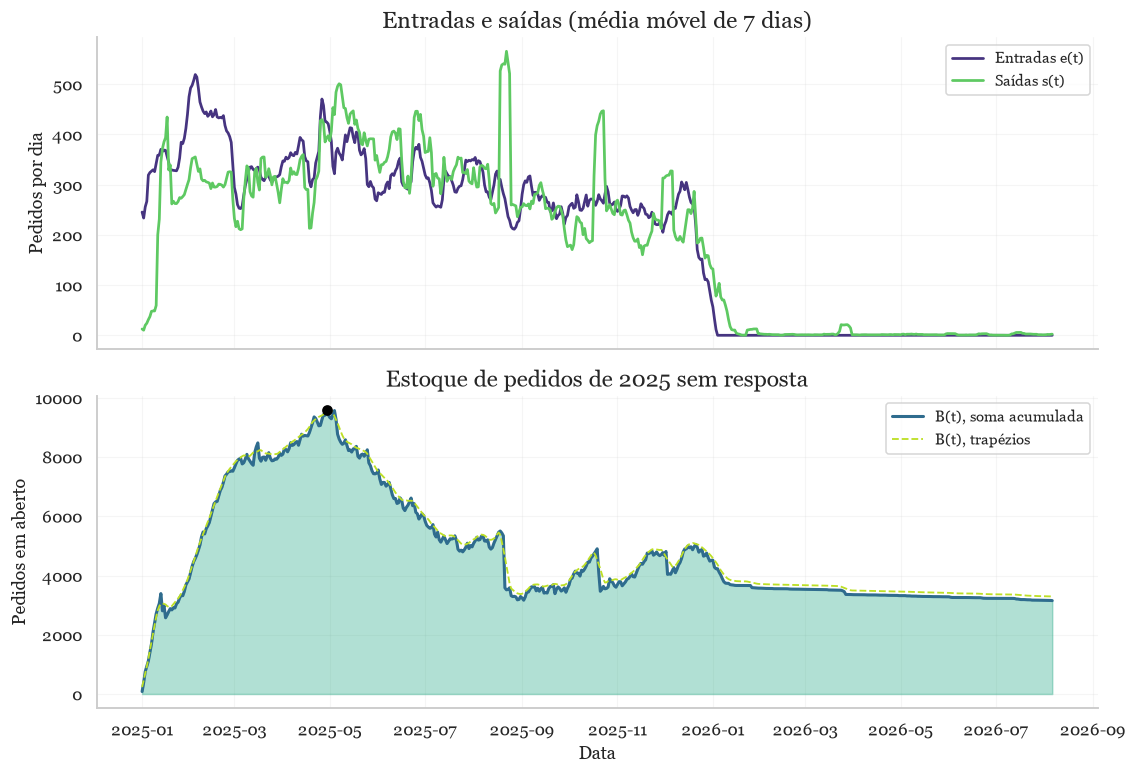

In [12]:
entradas = coorte["entradas"].to_numpy(dtype=float)
saidas = (coorte["finalizadas"] + coorte["canceladas"]).to_numpy(dtype=float)
dias = np.arange(len(coorte), dtype=float)
saldo = entradas - saidas
estoque = np.cumsum(saldo)

suavizar = lambda v: pd.Series(v).rolling(7, center=True, min_periods=1).mean().to_numpy()
saldo_suave = suavizar(saldo)
estoque_continuo = cumulative_trapezoid(saldo_suave, dias, initial=0) + saldo_suave[0]

i_pico = int(np.argmax(estoque))
abertos_final = int(estoque[-1])
assert abertos_final == total_2025 - int(coorte["finalizadas"].sum()) - int(coorte["canceladas"].sum())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 7.2), sharex=True)
ax1.plot(coorte["data"], suavizar(entradas), color=cmap(0.15), lw=1.8, label="Entradas e(t)")
ax1.plot(coorte["data"], suavizar(saidas), color=cmap(0.75), lw=1.8, label="Saídas s(t)")
ax1.set(ylabel="Pedidos por dia", title="Entradas e saídas (média móvel de 7 dias)")
ax1.legend()
ax2.fill_between(coorte["data"], estoque, color=cmap(0.6), alpha=0.35)
ax2.plot(coorte["data"], estoque, color=cmap(0.35), lw=2, label="B(t), soma acumulada")
ax2.plot(coorte["data"], estoque_continuo, color=cmap(0.9), lw=1.2, ls="--", label="B(t), trapézios")
ax2.scatter([coorte["data"][i_pico]], [estoque[i_pico]], color="black", zorder=3)
ax2.set(ylabel="Pedidos em aberto", xlabel="Data", title="Estoque de pedidos de 2025 sem resposta")
ax2.legend()
plt.tight_layout()
plt.show()

**2.b — A derivada do estoque e o pico da fila.** Pelo Teorema Fundamental do Cálculo, $B'(t)=e(t)-s(t)$. O estoque cresce enquanto entram mais pedidos do que saem e atinge o máximo quando a derivada troca de sinal, de positiva para negativa.

In [13]:
fim_2025 = int(np.where(coorte["data"] == "2025-12-31")[0][0])
saldo_jan_abr = saldo[(coorte["data"] < "2025-05-01").to_numpy()].sum()
saldo_mai_ago = saldo[((coorte["data"] >= "2025-05-01") & (coorte["data"] < "2025-09-01")).to_numpy()].sum()
assert np.isclose(estoque[i_pico] - estoque[0], saldo[1:i_pico + 1].sum())   # TFC na forma discreta

display(pd.DataFrame({
    "Indicador": ["Pico do estoque", "Data do pico", "Estoque em 31/12/2025",
                  f"Ainda abertos em {coorte['data'].iloc[-1]:%d/%m/%Y}", "Variação jan–abr", "Variação mai–ago"],
    "Valor": [f"{estoque[i_pico]:.0f} pedidos", f"{coorte['data'][i_pico]:%d/%m/%Y}", f"{estoque[fim_2025]:.0f} pedidos",
              f"{abertos_final} pedidos ({100*abertos_final/total_2025:.2f}%)", f"{saldo_jan_abr:+.0f}", f"{saldo_mai_ago:+.0f}"],
}))

display(Markdown(f"""
**Interpretação.** De janeiro a abril, $B'(t)>0$ na maior parte dos dias: a fila cresceu **{saldo_jan_abr:+.0f}** pedidos
e chegou ao pico de **{estoque[i_pico]:.0f} pedidos em aberto em {coorte['data'][i_pico]:%d/%m/%Y}**. Depois, as saídas
superaram as entradas e o estoque caiu **{saldo_mai_ago:.0f}** pedidos entre maio e agosto. A queda brusca no fim de
agosto, com cerca de 550 saídas por dia, sugere um **fechamento de pedidos em lote**, que deveria ser confirmado com o órgão
responsável. Em {coorte['data'].iloc[-1]:%d/%m/%Y}, **{abertos_final} pedidos de 2025** ({100*abertos_final/total_2025:.1f}%) ainda não
tinham resposta.

**Para o Olho na Via:** o sinal de $B'(t)$ é um **indicador antecipado de sobrecarga**. Se a média móvel de $e(t)-s(t)$
fica positiva por semanas seguidas, como em fevereiro e março, a prioridade (IPV) deve ser recalibrada e as equipes, reforçadas
**antes** de a fila chegar ao pico.
"""))

,Indicador,Valor
0,Pico do estoque,9589 pedidos
1,Data do pico,29/04/2025
2,Estoque em 31/12/2025,4515 pedidos
3,Ainda abertos em 06/08/2026,3153 pedidos (2.79%)
4,Variação jan–abr,+9434
5,Variação mai–ago,-6143



**Interpretação.** De janeiro a abril, $B'(t)>0$ na maior parte dos dias: a fila cresceu **+9434** pedidos
e chegou ao pico de **9589 pedidos em aberto em 29/04/2025**. Depois, as saídas
superaram as entradas e o estoque caiu **-6143** pedidos entre maio e agosto. A queda brusca no fim de
agosto, com cerca de 550 saídas por dia, sugere um **fechamento de pedidos em lote**, que deveria ser confirmado com o órgão
responsável. Em 06/08/2026, **3153 pedidos de 2025** (2.8%) ainda não
tinham resposta.

**Para o Olho na Via:** o sinal de $B'(t)$ é um **indicador antecipado de sobrecarga**. Se a média móvel de $e(t)-s(t)$
fica positiva por semanas seguidas, como em fevereiro e março, a prioridade (IPV) deve ser recalibrada e as equipes, reforçadas
**antes** de a fila chegar ao pico.


---

# **Parte 3 — Quanto tempo um buraco espera**

**3.a — A curva de sobrevivência observada.** Para cada pedido de 2025 que não foi cancelado, medimos os dias entre a abertura e a finalização. $S(d)$ é a fração que **ainda não tinha sido reparada** após $d$ dias. Como o acompanhamento vai até 06/08/2026, a curva é completa para $0\leq d\leq 218$.

In [14]:
d_obs = sobrevivencia["dias"].to_numpy(dtype=float)
S_obs = sobrevivencia["fracao_sem_reparo"].to_numpy(dtype=float)
mediana = int(d_obs[np.argmax(S_obs <= 0.5)])
display(pd.DataFrame({"d (dias)": [0, 1, 7, 14, 30, 60, 90, 180, 218],
                      "S(d)": [S_obs[i] for i in [0, 1, 7, 14, 30, 60, 90, 180, 218]]}).set_index("d (dias)"))
display(Markdown(f"""
- **{100*(1-S_obs[0]):.0f}%** dos pedidos foram finalizados no mesmo dia (d = 0).
- A **mediana** é de **{mediana} dias**, coerente com o "tempo médio de atendimento de seis dias" divulgado pela Prefeitura.
- Mas **{100*S_obs[30]:.1f}%** ainda estavam abertos após 30 dias, e **{100*S_obs[218]:.1f}%** após 218 dias.
"""))

,S(d)
d (dias),
0,0.8701
1,0.7616
7,0.4362
14,0.2628
30,0.1482
60,0.0813
90,0.0560
180,0.0361
218,0.0319



- **13%** dos pedidos foram finalizados no mesmo dia (d = 0).
- A **mediana** é de **6 dias**, coerente com o "tempo médio de atendimento de seis dias" divulgado pela Prefeitura.
- Mas **14.8%** ainda estavam abertos após 30 dias, e **3.2%** após 218 dias.


**3.b — Dois modelos exponenciais.** Testamos primeiro o modelo exponencial simples, $S(d)=S_0e^{-\lambda d}$, ajustado com **logaritmos** (Aula 06): $\ln S(d)=\ln S_0-\lambda d$ é uma reta, estimada por `polyfit`. Depois, um modelo com **duas exponenciais**, que representa dois grupos de buracos: os resolvidos rapidamente e uma **cauda lenta**:

$$
S(d)=A\,e^{-\lambda_r d}+B\,e^{-\lambda_l d}.
$$

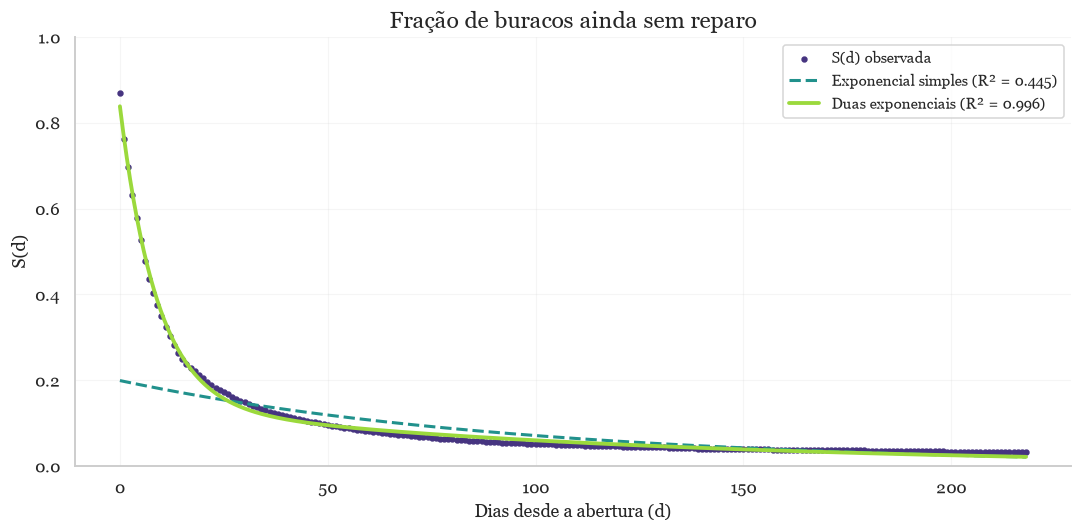


$$
S(d)=0.6958\,e^{-0.11207\,d}+0.1429\,e^{-0.00870\,d}
\qquad (R^2=0.9962)
$$

A exponencial simples ($R^2=0.445$) não consegue representar, ao mesmo tempo, a queda rápida
dos primeiros dias e a cauda longa. O modelo de dois termos separa os dois comportamentos:
**meia-vida de 6.2 dias** para os casos rápidos ($\ln 2/\lambda_r$) e **de 80 dias** para a cauda lenta ($\ln 2/\lambda_l$).


In [15]:
coef_log = np.polyfit(d_obs, np.log(S_obs), 1)
lam_1, S0_1 = -coef_log[0], np.exp(coef_log[1])
modelo_simples = lambda d: S0_1 * np.exp(-lam_1 * d)

def modelo_sobrevivencia(d, A, lam_r, B, lam_l):
    """Fração ainda sem reparo após d dias: casos rápidos (A, λr) e cauda lenta (B, λl)."""
    return A * np.exp(-lam_r * d) + B * np.exp(-lam_l * d)

params, _ = curve_fit(modelo_sobrevivencia, d_obs, S_obs, p0=[0.8, 0.15, 0.1, 0.01],
                      bounds=(0, [1, 5, 1, 5]), maxfev=50000)
A_s, lam_r, B_s, lam_l = params
S_modelo = lambda d: modelo_sobrevivencia(d, *params)

def r2(obs, est):
    return 1 - np.sum((obs - est) ** 2) / np.sum((obs - obs.mean()) ** 2)

malha_d = np.linspace(0, 218, 800)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(d_obs, S_obs, s=10, color=cmap(0.15), label="S(d) observada")
ax.plot(malha_d, modelo_simples(malha_d), color=cmap(0.5), lw=2, ls="--", label=f"Exponencial simples (R² = {r2(S_obs, modelo_simples(d_obs)):.3f})")
ax.plot(malha_d, S_modelo(malha_d), color=cmap(0.85), lw=2.5, label=f"Duas exponenciais (R² = {r2(S_obs, S_modelo(d_obs)):.3f})")
ax.set(title="Fração de buracos ainda sem reparo", xlabel="Dias desde a abertura (d)", ylabel="S(d)", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(f"""
$$
S(d)={A_s:.4f}\\,e^{{-{lam_r:.5f}\\,d}}+{B_s:.4f}\\,e^{{-{lam_l:.5f}\\,d}}
\\qquad (R^2={r2(S_obs, S_modelo(d_obs)):.4f})
$$

A exponencial simples ($R^2={r2(S_obs, modelo_simples(d_obs)):.3f}$) não consegue representar, ao mesmo tempo, a queda rápida
dos primeiros dias e a cauda longa. O modelo de dois termos separa os dois comportamentos:
**meia-vida de {np.log(2)/lam_r:.1f} dias** para os casos rápidos ($\\ln 2/\\lambda_r$) e **de {np.log(2)/lam_l:.0f} dias** para a cauda lenta ($\\ln 2/\\lambda_l$).
"""))

**3.c — Limites: comportamento nos extremos.** Calculamos com `sympy.limit` o que o modelo diz no início ($d\to0^+$) e no infinito ($d\to\infty$), inclusive para a taxa de reparo $h(d)$.

In [16]:
d = sp.symbols("d", nonnegative=True)
S_sym = sp.Float(A_s) * sp.exp(-sp.Float(lam_r) * d) + sp.Float(B_s) * sp.exp(-sp.Float(lam_l) * d)
dS_sym = sp.diff(S_sym, d)
h_sym = -dS_sym / S_sym
lim_zero = sp.limit(S_sym, d, 0, dir="+")
lim_inf = sp.limit(S_sym, d, sp.oo)
lim_h_inf = sp.limit(h_sym, d, sp.oo)
print("lim d→0+ S(d) =", sp.N(lim_zero, 6))
print("lim d→∞ S(d)  =", lim_inf)
print("lim d→∞ h(d)  =", sp.N(lim_h_inf, 6), "por dia")
assert np.isclose(float(lim_h_inf), lam_l)

display(Markdown(f"""
- $\\lim_{{d\\to0^+}}S(d)=A+B={float(lim_zero):.3f}$: o modelo reconhece que cerca de 16% dos pedidos se resolvem quase de imediato (o dado observado é {S_obs[0]:.3f}).
- $\\lim_{{d\\to\\infty}}S(d)=0$: no modelo, todo buraco **acaba** sendo reparado. Isso é uma **hipótese**: com 218 dias de dados,
  não é possível distinguir uma cauda muito lenta de uma fração que **nunca** é reparada.
- $\\lim_{{d\\to\\infty}}h(d)=\\lambda_l={lam_l:.4f}$ por dia: a chance diária de reparo de um buraco antigo cai para **{100*lam_l:.2f}% ao dia**.
"""))

lim d→0+ S(d) = 0.838715
lim d→∞ S(d)  = 0
lim d→∞ h(d)  = 0.00869670 por dia



- $\lim_{d\to0^+}S(d)=A+B=0.839$: o modelo reconhece que cerca de 16% dos pedidos se resolvem quase de imediato (o dado observado é 0.870).
- $\lim_{d\to\infty}S(d)=0$: no modelo, todo buraco **acaba** sendo reparado. Isso é uma **hipótese**: com 218 dias de dados,
  não é possível distinguir uma cauda muito lenta de uma fração que **nunca** é reparada.
- $\lim_{d\to\infty}h(d)=\lambda_l=0.0087$ por dia: a chance diária de reparo de um buraco antigo cai para **0.87% ao dia**.


**3.d — Derivada: a velocidade dos reparos.** $S'(d)$ mede quantos pedidos (em fração do total) são reparados por dia, $d$ dias após a abertura. Dividindo por $S(d)$, obtemos $h(d)$, a chance diária de reparo de quem **ainda está esperando**:

$$
S'(d)=-A\lambda_r e^{-\lambda_r d}-B\lambda_l e^{-\lambda_l d},\qquad h(d)=-\frac{S'(d)}{S(d)}.
$$

,S'(d) (por dia),h(d) (% ao dia)
d (dias),,
1,-0.0709,9.2893
7,-0.0368,8.1317
30,-0.0037,2.7274
90,-0.0006,0.8743


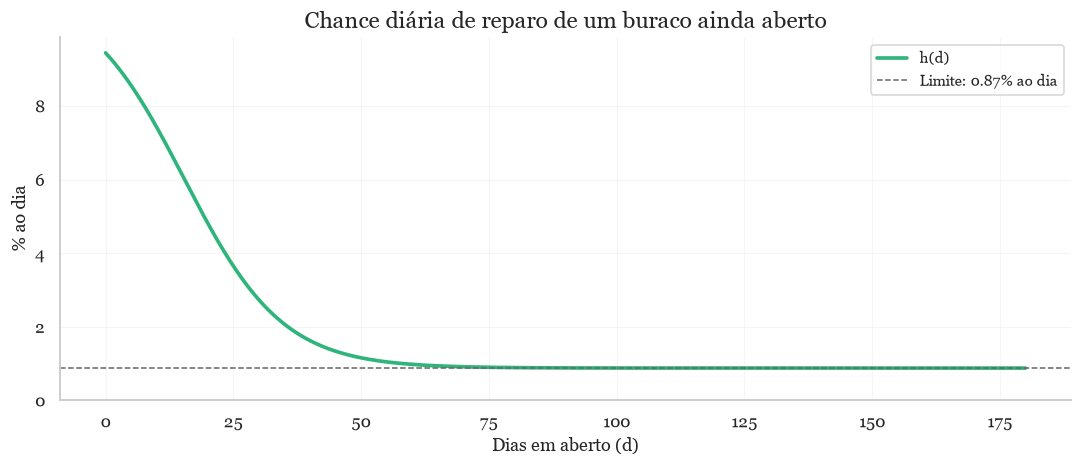


**Interpretação.** $h(d)$ é **decrescente**: um buraco aberto há 1 dia tem cerca de 9% de chance de ser reparado
no dia seguinte; um aberto há 90 dias, menos de 1%. **Quanto mais tempo um pedido fica na fila, menor a chance de ser
atendido.** Esse comportamento justifica a variável $T$ (tempo em aberto) no Índice de Prioridade do Olho na Via:
sem ela, os casos antigos tendem a ficar esquecidos.


In [17]:
dS_num = sp.lambdify(d, dS_sym, "numpy")
h_num = sp.lambdify(d, h_sym, "numpy")
linhas = []
for dia in [1, 7, 30, 90]:
    manual = -A_s * lam_r * np.exp(-lam_r * dia) - B_s * lam_l * np.exp(-lam_l * dia)
    assert np.isclose(manual, dS_num(dia))
    linhas.append({"d (dias)": dia, "S'(d) (por dia)": manual, "h(d) (% ao dia)": 100 * h_num(dia)})
display(pd.DataFrame(linhas).set_index("d (dias)"))

malha_h = np.linspace(0, 180, 600)
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(malha_h, 100 * h_num(malha_h), color=cmap(0.65), lw=2.4, label="h(d)")
ax.axhline(100 * lam_l, color="0.4", ls="--", lw=1, label=f"Limite: {100*lam_l:.2f}% ao dia")
ax.set(title="Chance diária de reparo de um buraco ainda aberto", xlabel="Dias em aberto (d)", ylabel="% ao dia", ylim=(0, None))
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(r"""
**Interpretação.** $h(d)$ é **decrescente**: um buraco aberto há 1 dia tem cerca de 9% de chance de ser reparado
no dia seguinte; um aberto há 90 dias, menos de 1%. **Quanto mais tempo um pedido fica na fila, menor a chance de ser
atendido.** Esse comportamento justifica a variável $T$ (tempo em aberto) no Índice de Prioridade do Olho na Via:
sem ela, os casos antigos tendem a ficar esquecidos.
"""))

**3.e — Integral imprópria: o tempo médio de espera.** O tempo médio até o reparo é a área sob $S(d)$. Como o domínio é infinito, a integral é **imprópria**, definida por um limite:

$$
\mathbb{E}[T]=\int_0^{\infty}S(d)\,dd=\lim_{T\to\infty}\int_0^{T}\left(Ae^{-\lambda_r d}+Be^{-\lambda_l d}\right)dd
=\lim_{T\to\infty}\left[\frac{A}{\lambda_r}\left(1-e^{-\lambda_r T}\right)+\frac{B}{\lambda_l}\left(1-e^{-\lambda_l T}\right)\right]=\frac{A}{\lambda_r}+\frac{B}{\lambda_l}.
$$

,∫₀ᵀ S(d) dd (dias)
T (dias),
7,4.3459
30,9.7671
90,15.1285
218,20.1733
365,21.9540
730,22.6125
2000,22.6412


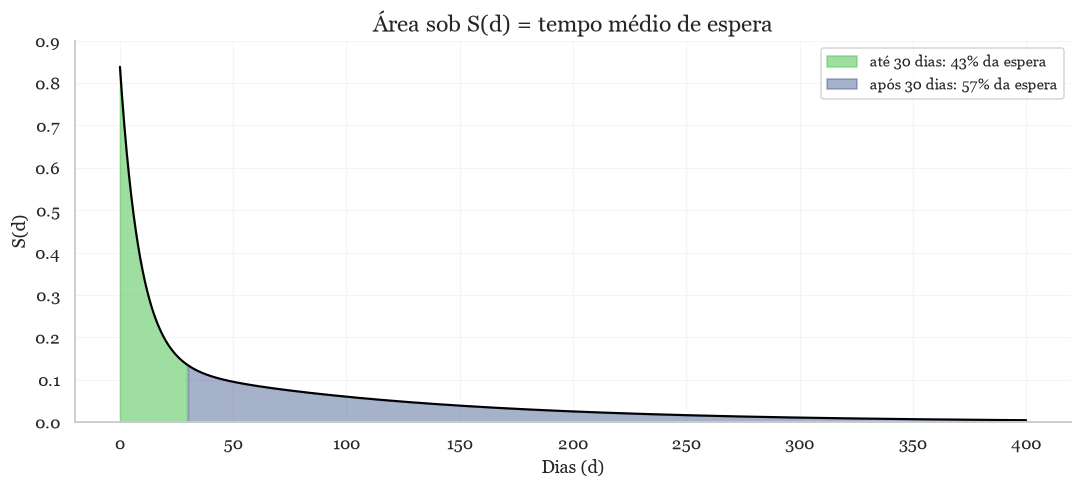


- **Tempo médio previsto:** $A/\lambda_r+B/\lambda_l=\boxed{22.64\ \text{dias}}$, quase **quatro vezes a mediana** de 6 dias.
- Até 218 dias: trapézios sobre os dados = **20.28 dias**; Simpson próprio sobre o modelo = **20.17 dias**.
- A tabela mostra o limite em ação: $\int_0^T S$ se estabiliza em 22.64 quando $T$ cresce.
- **57% de toda a espera acontece depois do 30º dia**, concentrada em apenas **13% dos pedidos**.
- Em 2025: 112540 pedidos × 22.6 dias ≈ **2.55 milhões de buraco-dias** de espera.


In [18]:
media = float(sp.integrate(S_sym, (d, 0, sp.oo)))
assert np.isclose(media, A_s / lam_r + B_s / lam_l)
area_ate = lambda T: A_s / lam_r * (1 - np.exp(-lam_r * T)) + B_s / lam_l * (1 - np.exp(-lam_l * T))
display(pd.DataFrame({"T (dias)": [7, 30, 90, 218, 365, 730, 2000],
                      "∫₀ᵀ S(d) dd (dias)": [area_ate(T) for T in [7, 30, 90, 218, 365, 730, 2000]]}).set_index("T (dias)"))

def simpson_composto(f, a, b, n):
    """Regra de Simpson 1/3 composta, implementada explicitamente (n par)."""
    if n <= 0 or n % 2:
        raise ValueError("A regra clássica exige n par e positivo.")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    passo = (b - a) / n
    return passo / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

area_trap = trapezoid(S_obs, d_obs)
area_simpson = simpson_composto(S_modelo, 0, 218, 218)
assert np.isclose(area_simpson, area_ate(218), rtol=1e-6)

cauda_30 = 1 - area_ate(30) / media
n_validos = int(round(sobrevivencia["reparados_ate_d"].iloc[-1] / (1 - S_obs[-1])))

malha_c = np.linspace(0, 400, 800)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(malha_c, S_modelo(malha_c), where=malha_c <= 30, color=cmap(0.75), alpha=0.6, label=f"até 30 dias: {100*(1-cauda_30):.0f}% da espera")
ax.fill_between(malha_c, S_modelo(malha_c), where=malha_c >= 30, color=cmap(0.25), alpha=0.45, label=f"após 30 dias: {100*cauda_30:.0f}% da espera")
ax.plot(malha_c, S_modelo(malha_c), color="black", lw=1.4)
ax.set(title="Área sob S(d) = tempo médio de espera", xlabel="Dias (d)", ylabel="S(d)", ylim=(0, 0.9))
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(f"""
- **Tempo médio previsto:** $A/\\lambda_r+B/\\lambda_l=\\boxed{{{media:.2f}\\ \\text{{dias}}}}$, quase **quatro vezes a mediana** de {mediana} dias.
- Até 218 dias: trapézios sobre os dados = **{area_trap:.2f} dias**; Simpson próprio sobre o modelo = **{area_simpson:.2f} dias**.
- A tabela mostra o limite em ação: $\\int_0^T S$ se estabiliza em {media:.2f} quando $T$ cresce.
- **{100*cauda_30:.0f}% de toda a espera acontece depois do 30º dia**, concentrada em apenas **{100*S_modelo(30):.0f}% dos pedidos**.
- Em 2025: {n_validos} pedidos × {media:.1f} dias ≈ **{n_validos*media/1e6:.2f} milhões de buraco-dias** de espera.
"""))

**3.f — O custo do atraso e a convergência da integral.** Retomamos a ideia da proposta inicial como **cenário**: suponha que o dano causado por um buraco (a quedas, pneus, sinistros) cresça com o tempo como $e^{kd}$, com $k\geq0$ desconhecido. O dano acumulado esperado, relativo, é

$$
D(k)=\int_0^{\infty}S(d)\,e^{kd}\,dd=\frac{A}{\lambda_r-k}+\frac{B}{\lambda_l-k},\qquad\text{válido somente se }k<\lambda_l .
$$

Se $k\geq\lambda_l$, a integral **diverge**: o limite não existe e o dano esperado é infinito.

In [19]:
k = sp.symbols("k", real=True)
A_g, B_g, lr_g, ll_g = sp.symbols("A B lambda_r lambda_l", positive=True)
D_geral = A_g / (lr_g - k) + B_g / (ll_g - k)
print("lim k→λl⁻ D(k) =", sp.limit(D_geral, k, ll_g, dir="-"))
D_k = D_geral.subs({A_g: A_s, B_g: B_s, lr_g: lam_r, ll_g: lam_l})
dD = sp.diff(D_k, k)

cenarios = []
for kk in [0.0, 0.002, 0.005, 0.008]:
    valor = float(D_k.subs(k, kk))
    numerico = quad(lambda x: A_s * np.exp((kk - lam_r) * x) + B_s * np.exp((kk - lam_l) * x), 0, 20000, limit=500)[0]
    assert np.isclose(valor, numerico, rtol=1e-6)
    cenarios.append({"k (por dia)": kk, "D(k)": valor, "D(k)/D(0)": valor / media, "dD/dk": float(dD.subs(k, kk))})
display(pd.DataFrame(cenarios).set_index("k (por dia)"))

display(Markdown(f"""
**Interpretação.** O limiar de convergência é a taxa da **cauda lenta**, $\\lambda_l={lam_l:.4f}$ por dia, e não a dos
casos rápidos. Se o dano de um buraco cresce 0,5% ao dia, o custo esperado **dobra** em relação ao cenário sem crescimento;
com 0,8% ao dia, fica mais de **9 vezes** maior; acima de {100*lam_l:.2f}% ao dia, **diverge**.
A derivada $dD/dk>0$, crescente em $k$, mostra que a sensibilidade explode perto do limiar.

**Conclusão da Parte 3:** encurtar a **cauda** (aumentar $\\lambda_l$) vale muito mais do que acelerar a mediana.
Essa é a contribuição matemática central para o Olho na Via.
"""))

lim k→λl⁻ D(k) = oo


,D(k),D(k)/D(0),dD/dk
k (por dia),,,
0.0000,22.6412,1.0000,1944.9166
0.0020,27.6617,1.2217,3244.1084
0.0050,45.1572,1.9945,10518.2814
0.0080,211.8092,9.3550,294486.1547



**Interpretação.** O limiar de convergência é a taxa da **cauda lenta**, $\lambda_l=0.0087$ por dia, e não a dos
casos rápidos. Se o dano de um buraco cresce 0,5% ao dia, o custo esperado **dobra** em relação ao cenário sem crescimento;
com 0,8% ao dia, fica mais de **9 vezes** maior; acima de 0.87% ao dia, **diverge**.
A derivada $dD/dk>0$, crescente em $k$, mostra que a sensibilidade explode perto do limiar.

**Conclusão da Parte 3:** encurtar a **cauda** (aumentar $\lambda_l$) vale muito mais do que acelerar a mediana.
Essa é a contribuição matemática central para o Olho na Via.


---

# **Parte 4 — Decisão: o que os resultados indicam para o Olho na Via**

In [20]:
decisao = pd.DataFrame([
    ["Demanda (Parte 1)", f"Demanda caiu ao longo de 2025 (q' < 0), queda mais rápida em t ≈ {t_inflexao:.0f}; extrapolação erra 2026 em {erro_26:+.0f}%",
     "Recalibrar o dimensionamento a cada trimestre com dados novos; não extrapolar polinômios"],
    ["Estoque (Parte 2)", f"Fila subiu até {estoque[i_pico]:.0f} pedidos em {coorte['data'][i_pico]:%d/%m}; B'(t) = e(t) − s(t) antecipa a sobrecarga",
     "Alerta no painel do gestor quando a média de 14 dias de e(t) − s(t) ficar positiva"],
    ["Espera (Parte 3)", f"Mediana de {mediana} dias, média de {media:.1f}; {100*cauda_30:.0f}% da espera ocorre após 30 dias",
     "Verificação obrigatória e reabertura automática de todo chamado com mais de 30 dias"],
    ["Prioridade (Parte 3)", "h(d) decrescente: casos antigos têm cada vez menos chance de reparo",
     "Manter a variável T (tempo em aberto) no IPV, com peso crescente"],
    ["Custo do atraso (Parte 3)", f"D(k) converge só se k < λl = {100*lam_l:.2f}% ao dia",
     "Meta principal: aumentar λl (encurtar a cauda), não só reduzir a mediana"],
], columns=["Análise", "Resultado matemático", "Decisão para o protótipo"])
display(decisao)

,Análise,Resultado matemático,Decisão para o protótipo
0,Demanda (Parte 1),"Demanda caiu ao longo de 2025 (q' < 0), queda ...",Recalibrar o dimensionamento a cada trimestre ...
1,Estoque (Parte 2),Fila subiu até 9589 pedidos em 29/04; B'(t) = ...,Alerta no painel do gestor quando a média de 1...
2,Espera (Parte 3),"Mediana de 6 dias, média de 22.6; 57% da esper...",Verificação obrigatória e reabertura automátic...
3,Prioridade (Parte 3),h(d) decrescente: casos antigos têm cada vez m...,"Manter a variável T (tempo em aberto) no IPV, ..."
4,Custo do atraso (Parte 3),D(k) converge só se k < λl = 0.87% ao dia,Meta principal: aumentar λl (encurtar a cauda)...


---

# **Conclusão e limitações**

Com dados reais da cidade, o cálculo transformou uma pergunta operacional em números verificáveis:

- **Limites** mostraram que polinômios não podem ser extrapolados (eles tendem a $\pm\infty$), definiram a derivada pela definição e decidiram a convergência do custo do atraso.
- **Derivadas** identificaram quando a demanda cai mais rápido, quando a fila de pedidos cresce ($B'(t)>0$) e que a chance diária de reparo diminui com o tempo.
- **Integrais** reproduziram o total anual de pedidos, construíram o estoque em aberto e calcularam, por uma integral imprópria, o tempo médio de espera de **22,6 dias**, bem acima da mediana de 6 dias.

**Limitações:**

- Pedidos não são buracos: a demanda reprimida e os buracos nunca reportados não aparecem nos dados.
- A Parte 1 usa um único ano para o ajuste.
- O modelo de sobrevivência supõe que todo buraco acaba reparado ($\lim S=0$).
- A taxa de crescimento do dano, $k$, é hipotética e foi tratada como cenário.
- A queda brusca do estoque em agosto de 2025 precisa ser confirmada com a Prefeitura.

---

# **Referências**

- PREFEITURA DE SÃO PAULO. *Dados do SP156 – Solicitações* (1º TRI 2025 a 3º TRI 2026). Portal de Dados Abertos. Disponível em: https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156. Acesso em: 09 nov. 2026.
- PREFEITURA DE SÃO PAULO. *Glossário da Base de Dados do SP156 – 2020 em diante* (atualizado em 10/08/2026).
- BNEWS SÃO PAULO. *Mesmo após recapeamento, SP registra quase 52 mil pedidos de tapa-buraco*. 09 ago. 2026 (números oficiais da SMSUB usados na auditoria).
- STEWART, J. *Cálculo*, v. 1. Cengage. Capítulos de limites, derivadas e integrais impróprias.
- OPENSTAX. *Calculus Volume 1 e 2*, seções 2.2 (limites), 3.1 (derivada pela definição), 3.6 (integração numérica) e 3.7 (integrais impróprias).
- Notebooks das Aulas 05, 06, 07, 12 a 16, 18, 19 e da revisão para a GS de Differentiated Problem Solving (FIAP, 2026.2).